# Lucrare de laborator nr. 1 — Daniel Panuta
## Generator de text caracter-cu-caracter folosind LSTM

### Scopul lucrării
În această lucrare am implementat și antrenat un model generativ bazat pe LSTM, capabil să genereze text caracter-cu-caracter.

În cadrul lucrării am realizat următoarele etape:
- încărcarea și analiza unui corpus textual;
- construirea vocabularului de caractere;
- transformarea textului în reprezentare numerică;
- construirea secvențelor de antrenare;
- implementarea unei rețele LSTM;
- antrenarea și validarea modelului;
- analiza funcției de pierdere;
- generarea de text nou;
- evaluarea influenței parametrului `temperature` asupra textului generat.

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
import urllib.request

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 2. Încărcarea corpusului textual

Pentru antrenarea modelului LSTM am utilizat un corpus textual în limba engleză, descărcat din Project Gutenberg. Fișierul folosit este `Man's descent from the gods`, atribuit lui Gilbert Murray; nu este un corpus Shakespeare.

Corpusul este descărcat automat prin `urllib.request` și conține 491.100 de caractere după încărcare. Alegerea acestui corpus îi permite modelului să observe modele și dependențe între caractere.

În această lucrare, modelul va funcționa la nivel de caracter, ceea ce înseamnă că textul nu este împărțit în cuvinte, ci în caractere individuale. Scopul modelului este să învețe, pe baza unei secvențe de caractere, care este cel mai probabil caracter următor.

In [2]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)
corpus_path = DATA_DIR / "lstm_corpus.txt"
url = "https://www.gutenberg.org/cache/epub/79572/pg79572.txt"

fallback_text = """
Rețelele neuronale recurente pot învăța dependențe din secvențe de text.
O celulă LSTM păstrează informații utile și uită informațiile care nu mai sunt relevante.
Un generator caracter-cu-caracter primește o fereastră de caractere și prezice următorul caracter.
Calitatea textului depinde de corpus, de lungimea secvenței și de temperatura folosită la eșantionare.
În acest laborator analizăm antrenarea, validarea și efectul temperaturii asupra creativității textului generat.
""".strip()

try:
    if not corpus_path.exists():
        urllib.request.urlretrieve(url, corpus_path)
    raw_text = corpus_path.read_text(encoding="utf-8")
    print(f"Corpus încărcat din: {corpus_path}")
except (OSError, urllib.error.URLError) as exc:
    print(f"Descărcarea nu a reușit ({type(exc).__name__}); se folosește fallback-ul local.")
    raw_text = fallback_text

Corpus încărcat din: data/lstm_corpus.txt


## 3. Citirea și analiza inițială a corpusului

După descărcare, fișierul este citit și convertit într-un șir de caractere Unicode.

În această etapă se verifică:
- dimensiunea totală a corpusului;
- conținutul inițial al textului;
- faptul că datele au fost încărcate corect.

Această analiză inițială este importantă deoarece permite verificarea datelor înainte de preprocesare și antrenare.

In [3]:
text = " ".join(raw_text.replace("\r", "").split())
if len(text) < 2_000:
    text = (text + " " + text) * 20

print(f"Lungimea corpusului: {len(text):,} caractere")
print(f"Mostră: {text[:250]}...")

Lungimea corpusului: 491,100 caractere
Mostră: The Project Gutenberg eBook of Man's descent from the gods This eBook is for the use of anyone anywhere in the United States and most other parts of the world at no cost and with almost no restrictions whatsoever. You may copy it, give it away or re-...


## 4. Construirea vocabularului de caractere

Deoarece modelul este de tip character-level, fiecare caracter distinct din corpus reprezintă o unitate separată de învățare.

Vocabularul este format din toate caracterele unice existente în text, inclusiv:
- litere mari și mici;
- cifre, dacă apar;
- spații;
- semne de punctuație;
- caractere speciale precum newline.

Dimensiunea vocabularului determină și dimensiunea stratului final al rețelei, deoarece modelul trebuie să estimeze probabilitatea pentru fiecare caracter posibil.

In [4]:
vocab = sorted(set(text))

print("Vocabulary size:", len(vocab))
print("\nCharacters in vocabulary:")
print(vocab)

Vocabulary size: 154

Characters in vocabulary:
[' ', '!', '#', '$', '%', "'", '(', ')', '*', '+', ',', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', ';', '=', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', '[', ']', '^', '_', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '{', '|', '°', '·', '½', 'Â', 'Æ', 'É', 'Ü', 'à', 'â', 'ã', 'ä', 'æ', 'ç', 'è', 'é', 'ê', 'ë', 'î', 'ô', 'ö', 'û', 'ü', 'ā', 'œ', 'Β', 'Θ', 'Λ', 'Μ', 'Π', 'ά', 'ή', 'ί', 'α', 'γ', 'δ', 'ε', 'η', 'θ', 'ι', 'κ', 'μ', 'ν', 'ο', 'π', 'ρ', 'ς', 'σ', 'τ', 'υ', 'χ', 'ω', 'ό', 'ύ', 'ἐ', 'ἰ', 'ὑ', 'ὸ', 'ῆ', 'ῖ', 'ῦ', '—', '‘', '’', '“', '”', '•', '™', '⅔']


## 5. Codificarea caracterelor în valori numerice

Rețeaua neuronală nu poate procesa direct caractere precum `A`, `b`, `?` sau spații. Din acest motiv, fiecare caracter din vocabular este asociat cu un identificator numeric unic.

Se construiesc două mapări:

- `char_to_idx` — transformă caracterul în ID numeric;
- `idx_to_char` — transformă ID-ul numeric înapoi în caracter.

Ulterior, întregul corpus este convertit într-o secvență de numere întregi.

Această reprezentare numerică permite utilizarea textului ca date de intrare pentru modelul LSTM.

In [5]:
print("Total characters:", len(text))
print("Unique characters:", len(vocab))

print("\nExample characters:")
for i, char in enumerate(vocab[:20]):
    print(i, repr(char))

Total characters: 491100
Unique characters: 154

Example characters:
0 ' '
1 '!'
2 '#'
3 '$'
4 '%'
5 "'"
6 '('
7 ')'
8 '*'
9 '+'
10 ','
11 '-'
12 '.'
13 '/'
14 '0'
15 '1'
16 '2'
17 '3'
18 '4'
19 '5'


In [6]:
char_to_idx = {
    char: idx
    for idx, char in enumerate(vocab)
}

idx_to_char = np.array(vocab)

In [7]:
for char in ["a", "b", "c", " ", "/"]: 
    print(repr(char), "->", char_to_idx[char])

'a' -> 58
'b' -> 59
'c' -> 60
' ' -> 0
'/' -> 13


## 6. Transformarea corpusului într-o secvență numerică

După definirea mapării caracter–ID, întregul corpus este convertit într-o secvență de numere întregi.

Fiecare caracter este înlocuit cu identificatorul său numeric, păstrându-se ordinea originală a textului.

Această reprezentare numerică va fi utilizată ulterior pentru construirea secvențelor de antrenare ale modelului LSTM.

In [8]:
text_as_int = np.array(
    [char_to_idx[char] for char in text]
)

print("Original text:")
print(text[200:100])

print("\nEncoded text:")
print(text_as_int[200:100])

Original text:


Encoded text:
[]


## 7. Verificarea codificării și decodificării

Pentru a verifica dacă maparea a fost construită corect, un fragment din corpus este:

1. transformat din caractere în ID-uri numerice;
2. reconstruit ulterior din ID-uri în caractere.

Dacă textul reconstruit este identic cu textul inițial, codificarea este corectă.

In [9]:
sample_text = text[200:50]

encoded_sample = [char_to_idx[c] for c in sample_text]
decoded_sample = "".join(idx_to_char[encoded_sample])

print("Original sample:")
print(repr(sample_text))

print("\nEncoded sample:")
print(encoded_sample)

print("\nDecoded sample:")
print(repr(decoded_sample))

Original sample:
''

Encoded sample:
[]

Decoded sample:
''


## 8. Crearea secvențelor de caractere

Modelul LSTM nu va primi întregul corpus simultan. Textul este împărțit în secvențe mai mici, cu lungimea de 100 de caractere.

Pentru fiecare exemplu de antrenare sunt utilizate 101 caractere:
- primele 100 de caractere formează secvența de intrare;
- secvența țintă este obținută prin deplasarea textului cu un caracter.

Astfel, modelul învață să prezică caracterul următor pentru fiecare poziție din secvență.

O lungime de 100 de caractere oferă modelului suficient context pentru a învăța relații locale și structuri ale textului, fără a face procesul de antrenare excesiv de costisitor.

In [10]:
seq_length = 100

char_dataset = tf.data.Dataset.from_tensor_slices(text_as_int)

print("Sequence length:", seq_length)

print("\nFirst 10 characters from dataset:")
for i in char_dataset.take(10):
    print(repr(idx_to_char[i.numpy()]))

Sequence length: 100

First 10 characters from dataset:
np.str_('T')
np.str_('h')
np.str_('e')
np.str_(' ')
np.str_('P')
np.str_('r')
np.str_('o')
np.str_('j')
np.str_('e')
np.str_('c')


## 9. Gruparea caracterelor în secvențe

Caracterele sunt grupate în blocuri de câte 101 elemente.

Este utilizată valoarea `seq_length + 1`, deoarece avem nevoie de un caracter suplimentar pentru a construi perechea input-target.

Parametrul `drop_remainder=True` elimină ultimul bloc dacă acesta nu conține numărul complet de caractere necesar.

In [11]:
sequences = char_dataset.batch(
    seq_length + 1,
    drop_remainder=True
)

for item in sequences.take(1):
    print("Sequence length:", len(item.numpy()))

    print("\nDecoded sequence:\n")
    print("".join(idx_to_char[item.numpy()]))

Sequence length: 101

Decoded sequence:

The Project Gutenberg eBook of Man's descent from the gods This eBook is for the use of anyone anywhe


## 10. Construirea perechilor Input–Target

Pentru antrenarea modelului se construiesc perechi formate dintr-o secvență de intrare și o secvență țintă.

Secvența de intrare conține toate caracterele blocului, cu excepția ultimului caracter.

Secvența țintă conține aceeași secvență deplasată cu o poziție spre stânga.

De exemplu:

**Input:**

`HELL`

**Target:**

`ELLO`

Astfel, modelul învață următoarele relații:

- `H → E`
- `E → L`
- `L → L`
- `L → O`

Prin această metodă, LSTM învață să prezică următorul caracter pe baza caracterelor precedente.

In [12]:
def split_input_target(chunk):
    input_text = chunk[:-1]
    target_text = chunk[1:]

    return input_text, target_text


dataset = sequences.map(split_input_target)

## 11. Verificarea perechilor de antrenare

Pentru a verifica pregătirea corectă a datelor, este afișată prima pereche input-target.

Cele două secvențe trebuie să fie aproape identice, însă secvența target este deplasată cu un caracter.

Această deplasare permite modelului să învețe predicția caracterului următor la fiecare pas temporal.

In [13]:
for input_example, target_example in dataset.take(1):

    input_text = "".join(idx_to_char[input_example.numpy()])
    target_text = "".join(idx_to_char[target_example.numpy()])

    print("INPUT:\n")
    print(input_text)

    print("\n" + "=" * 70)

    print("\nTARGET:\n")
    print(target_text)

INPUT:

The Project Gutenberg eBook of Man's descent from the gods This eBook is for the use of anyone anywh


TARGET:

he Project Gutenberg eBook of Man's descent from the gods This eBook is for the use of anyone anywhe


## 12. Demonstrarea predicției caracter-cu-caracter

Pentru a evidenția modul în care este construită sarcina de învățare, sunt afișate primele perechi dintre caracterul de intrare și caracterul următor din secvență.

De exemplu:

`F → i`  
`i → r`  
`r → s`

La fiecare pas temporal, modelul trebuie să prezică următorul caracter pe baza caracterului curent și a contextului acumulat din caracterele precedente.

Aceasta reprezintă principiul de bază al generatorului de text caracter-cu-caracter.

In [14]:
for input_example, target_example in dataset.take(1):

    print("Primele 15 perechi caracter -> caracter următor:\n")

    for i in range(15):
        current_char = str(idx_to_char[input_example[i].numpy()])
        next_char = str(idx_to_char[target_example[i].numpy()])

        print(
            repr(current_char),
            "->",
            repr(next_char)
        )

Primele 15 perechi caracter -> caracter următor:

'T' -> 'h'
'h' -> 'e'
'e' -> ' '
' ' -> 'P'
'P' -> 'r'
'r' -> 'o'
'o' -> 'j'
'j' -> 'e'
'e' -> 'c'
'c' -> 't'
't' -> ' '
' ' -> 'G'
'G' -> 'u'
'u' -> 't'
't' -> 'e'


## 13. Împărțirea datasetului în Train și Validation

Pentru evaluarea corectă a modelului, datele sunt împărțite în două subseturi:

- **Training set (90%)** — utilizat pentru ajustarea ponderilor rețelei;
- **Validation set (10%)** — utilizat pentru evaluarea modelului pe secvențe care nu participă direct la actualizarea ponderilor.

Setul de validare permite urmărirea capacității modelului de a generaliza și ajută la identificarea fenomenului de overfitting.

În această implementare, secvențele sunt mai întâi separate în train și validation, iar ulterior doar datele de antrenare sunt amestecate (`shuffle`).

In [15]:
dataset_size = tf.data.experimental.cardinality(dataset).numpy()

train_size = int(0.9 * dataset_size)

train_dataset = dataset.take(train_size)
val_dataset = dataset.skip(train_size)

print("Total sequences:", dataset_size)
print("Training sequences:", train_size)
print("Validation sequences:", dataset_size - train_size)

Total sequences: 4862
Training sequences: 4375
Validation sequences: 487


## 14. Pregătirea datasetului pentru antrenare

Pentru o antrenare eficientă, secvențele sunt organizate în batch-uri.

Se utilizează următorii parametri:

- `BATCH_SIZE = 64` — modelul procesează simultan câte 64 de secvențe;
- `shuffle()` — amestecă secvențele de antrenare pentru a evita învățarea unei ordini fixe;
- `prefetch()` — pregătește următorul batch în timp ce modelul îl procesează pe cel curent, îmbunătățind eficiența.

Setul de validare nu este amestecat, deoarece acesta este utilizat doar pentru evaluare.

In [16]:
BATCH_SIZE = 64
BUFFER_SIZE = 10000

train_dataset = (
    train_dataset
    .shuffle(BUFFER_SIZE)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = (
    val_dataset
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training and validation datasets are ready.")

Training and validation datasets are ready.


## 15. Verificarea structurii datelor de intrare

Înainte de construirea modelului, este verificată forma unui batch.

Fiecare batch conține mai multe secvențe, iar fiecare secvență are lungimea de 100 de caractere.

Pentru un `BATCH_SIZE` de 64, forma așteptată este:

`(64, 100)`

Aceasta înseamnă:
- 64 exemple într-un batch;
- 100 de pași temporali pentru fiecare exemplu.

In [17]:
for input_batch, target_batch in train_dataset.take(1):

    print("Input batch shape:", input_batch.shape)
    print("Target batch shape:", target_batch.shape)

Input batch shape: (64, 100)
Target batch shape: (64, 100)


## 16. Arhitectura modelului LSTM

Modelul propus conține două straturi LSTM, ceea ce permite învățarea unor relații secvențiale mai complexe din corpus.

Arhitectura utilizată este:

1. **Embedding** — transformă ID-urile caracterelor în vectori densi;
2. **LSTM 1** — extrage dependențe secvențiale și transmite întreaga secvență către următorul strat;
3. **Dropout** — reduce riscul de overfitting;
4. **LSTM 2** — învață reprezentări secvențiale de nivel superior;
5. **Dropout** — regularizare suplimentară;
6. **Dense** — produce câte un scor pentru fiecare caracter posibil din vocabular.

Ambele straturi LSTM utilizează `return_sequences=True`.

Primul strat trebuie să transmită întreaga secvență către al doilea strat LSTM, iar al doilea strat trebuie să păstreze ieșirea pentru fiecare pas temporal, deoarece modelul realizează o predicție a următorului caracter la fiecare poziție din secvență.

Dimensiunea stratului final este egală cu dimensiunea vocabularului: 154 de caractere.

In [18]:
vocab_size = len(vocab)

embedding_dim = 128
lstm_units = 256

model = tf.keras.Sequential([

    tf.keras.layers.Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim
    ),

    tf.keras.layers.LSTM(
        lstm_units,
        return_sequences=True
    ),

    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.LSTM(
        lstm_units,
        return_sequences=True
    ),

    tf.keras.layers.Dropout(0.2),

    tf.keras.layers.Dense(vocab_size)
])

## 17. Vizualizarea arhitecturii modelului

Funcția `summary()` permite analizarea structurii rețelei și a numărului de parametri care vor fi învățați.

Înainte de afișarea sumarului este transmis un batch prin model pentru inițializarea completă a straturilor.

In [19]:
for input_batch, target_batch in train_dataset.take(1):
    sample_prediction = model(input_batch)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (64, 100, 128)         │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (64, 100, 256)         │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (64, 100, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (64, 100, 256)         │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (64, 100, 256)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (64, 100, 154)         │        39,578 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 978,842 (3.73 MB)

 Trainable params: 978,842 (3.73 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
print("Input shape:", input_batch.shape)
print("Prediction shape:", sample_prediction.shape)

Input shape: (64, 100)
Prediction shape: (64, 100, 154)


64  = numărul exemplelor din batch
100 = numărul pașilor temporali
65  = numărul caracterelor posibile

## 18. Verificarea resurselor de calcul

Antrenarea rețelelor LSTM poate necesita un volum semnificativ de calcule, în special atunci când modelul conține mai multe straturi recurente.

Pentru accelerarea procesului de antrenare se verifică disponibilitatea unui GPU în mediul Google Colab.

Utilizarea GPU nu modifică arhitectura sau rezultatul logic al modelului, dar poate reduce semnificativ timpul necesar pentru antrenare.

In [21]:
print("Available GPUs:")
print(tf.config.list_physical_devices("GPU"))

Available GPUs:
[]


## 19. Funcția de pierdere

Generatorul de text tratează predicția următorului caracter ca pe o problemă de clasificare multi-clasă.

Pentru fiecare poziție din secvență, modelul produce câte un scor (`logit`) pentru fiecare dintre cele 154 de caractere posibile din vocabular.

Este utilizată funcția `SparseCategoricalCrossentropy`, potrivită atunci când clasele țintă sunt reprezentate prin ID-uri numerice.

Modelul produce valori brute numite `logits`, de aceea este setat parametrul:

`from_logits=True`

Funcția de pierdere compară distribuția prezisă de model cu caracterul real și oferă o măsură numerică a erorii. În timpul antrenării, această eroare este minimizată prin backpropagation.

In [22]:
loss_function = tf.keras.losses.SparseCategoricalCrossentropy(
    from_logits=True
)

## 20. Evaluarea modelului înainte de antrenare

Înainte de antrenare, ponderile rețelei sunt inițializate aleatoriu.

Modelul poate efectua deja predicții, însă acestea nu sunt încă relevante, deoarece nu a învățat structura corpusului.

Se calculează funcția de pierdere pentru un batch inițial. Această valoare va fi comparată ulterior cu pierderea obținută după antrenare.

In [23]:
initial_loss = loss_function(
    target_batch,
    sample_prediction
)

print("Initial loss:", float(initial_loss))

Initial loss: 5.037782192230225


## 21. Compilarea modelului

Pentru antrenarea rețelei este utilizat optimizatorul Adam.

Adam ajustează ponderile modelului pe baza gradientului funcției de pierdere și este utilizat frecvent pentru antrenarea rețelelor neuronale profunde.

Modelul este compilat folosind:

- optimizatorul `Adam`;
- funcția de pierdere `SparseCategoricalCrossentropy`.

În această problemă, principalul indicator urmărit este funcția de pierdere, deoarece obiectivul modelului este estimarea distribuției probabilităților pentru următorul caracter.

In [24]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss=loss_function
)

print("Model compiled successfully.")

Model compiled successfully.


## 22. Configurarea mecanismelor de control al antrenării

Pentru controlul procesului de antrenare sunt utilizate două callback-uri.

### EarlyStopping

`EarlyStopping` urmărește valoarea `val_loss`. Dacă performanța pe setul de validare nu se îmbunătățește timp de mai multe epoci consecutive, antrenarea este oprită automat.

Această tehnică ajută la prevenirea overfitting-ului și evită antrenarea inutilă.

### ModelCheckpoint

`ModelCheckpoint` salvează automat versiunea modelului care obține cea mai mică valoare a `val_loss`.

Astfel, la finalul experimentului este păstrat cel mai performant model observat pe datele de validare.

In [25]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="best_lstm_text_generator.keras",
    monitor="val_loss",
    save_best_only=True
)

callbacks = [
    early_stopping,
    checkpoint
]

print("Callbacks configured.")

Callbacks configured.


## 23. Antrenarea modelului LSTM

Modelul este antrenat pe secvențele din `train_dataset`, iar după fiecare epocă este evaluat pe `val_dataset`.

O epocă reprezintă o parcurgere completă a setului de antrenare.

În timpul antrenării:

1. modelul efectuează propagarea înainte (`forward pass`);
2. este calculată funcția de pierdere;
3. eroarea este propagată înapoi prin rețea și în timp (`Backpropagation Through Time`);
4. optimizatorul Adam actualizează ponderile;
5. procesul se repetă pentru batch-urile următoare.

Sunt permise maximum 20 de epoci, însă `EarlyStopping` poate opri procesul mai devreme dacă performanța pe setul de validare nu se mai îmbunătățește.

In [26]:
EPOCHS = 20

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/20


/Users/danielpanuta/USM-Projects/GenAI/Lab1/venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


68/68 ━━━━━━━━━━━━━━━━━━━━ 21s 291ms/step - loss: 3.3015 - val_loss: 3.2963
Epoch 2/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 19s 278ms/step - loss: 2.8162 - val_loss: 2.9530
Epoch 3/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 19s 274ms/step - loss: 2.5413 - val_loss: 2.7846
Epoch 4/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 19s 274ms/step - loss: 2.4086 - val_loss: 2.6658
Epoch 5/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 19s 283ms/step - loss: 2.3093 - val_loss: 2.5932
Epoch 6/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 20s 288ms/step - loss: 2.2342 - val_loss: 2.5427
Epoch 7/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 20s 284ms/step - loss: 2.1733 - val_loss: 2.4890
Epoch 8/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 20s 294ms/step - loss: 2.1214 - val_loss: 2.4468
Epoch 9/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 20s 284ms/step - loss: 2.0794 - val_loss: 2.4069
Epoch 10/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 20s 290ms/step - loss: 2.0389 - val_loss: 2.3733
Epoch 11/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 20s 285ms/step - loss: 2.0020 - val_loss: 2.3381
Epoch 12/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 20s 290ms/ste

## 24. Analiza evoluției funcției de pierdere

Pentru evaluarea procesului de antrenare se compară valorile funcției de pierdere pentru setul de antrenare și setul de validare.

O scădere graduală a valorilor `loss` și `val_loss` indică faptul că modelul învață relațiile secvențiale din corpus.

Dacă `loss` continuă să scadă, dar `val_loss` începe să crească, acesta poate fi un semn de overfitting. În experimentul curent, ambele valori scad pe parcursul celor 20 de epoci, ceea ce indică o evoluție stabilă a modelului.

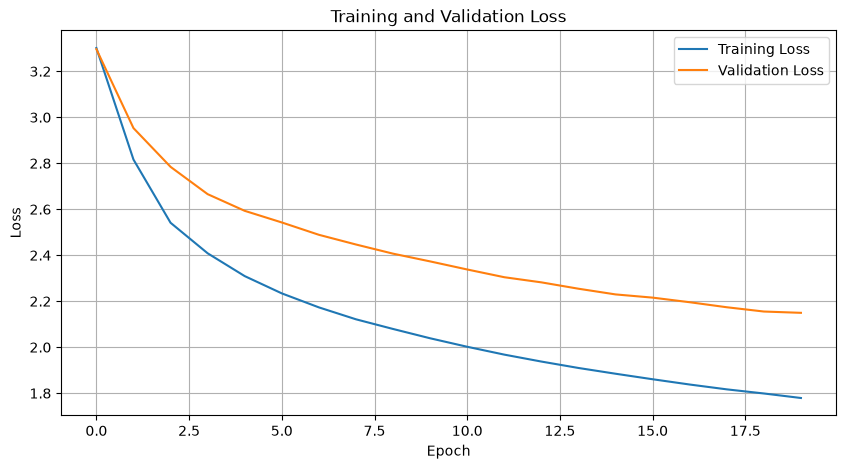

In [27]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.show()

## 25. Identificarea celei mai bune epoci

Cea mai bună epocă este considerată epoca în care `val_loss` atinge valoarea minimă.

Această valoare este importantă deoarece reflectă performanța modelului pe date care nu participă direct la actualizarea ponderilor.

In [28]:
val_losses = history.history["val_loss"]

best_epoch = np.argmin(val_losses) + 1
best_val_loss = np.min(val_losses)

print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 4))

Best epoch: 20
Best validation loss: 2.1496


## 26. Calculul perplexității

Pentru modelele de limbaj, o metrică frecvent utilizată este perplexitatea.

Perplexitatea poate fi interpretată intuitiv ca o măsură a incertitudinii modelului atunci când prezice următorul caracter.

Ea poate fi calculată pe baza funcției de pierdere prin relația:

`Perplexity = exp(loss)`

O valoare mai mică indică un model mai sigur în predicțiile sale.

In [29]:
best_perplexity = np.exp(best_val_loss)

print("Validation perplexity:", round(best_perplexity, 4))

Validation perplexity: 8.5813


În această lucrare este calculată perplexitatea la nivel de caracter (`character-level perplexity`), deoarece modelul prezice caractere, nu cuvinte sau tokeni.

## 27. Încărcarea celui mai bun model

În timpul antrenării, `ModelCheckpoint` a salvat automat versiunea cu cea mai bună performanță pe setul de validare.

Pentru etapa de generare este încărcată această versiune a modelului.

In [30]:
best_model = tf.keras.models.load_model(
    "best_lstm_text_generator.keras"
)

print("Best model loaded successfully.")

Best model loaded successfully.


## 28. Controlul diversității prin parametrul `temperature`

Modelul produce pentru fiecare poziție câte un scor pentru toate caracterele din vocabular.

Pentru generarea textului, aceste scoruri sunt transformate într-o distribuție de probabilitate, iar următorul caracter este eșantionat din această distribuție.

Parametrul `temperature` controlează nivelul de aleatorietate:

- valori mici, de exemplu `0.2`, produc text mai previzibil și repetitiv;
- valori medii, de exemplu `0.5–0.8`, oferă un echilibru între coerență și diversitate;
- valori mai mari, de exemplu `1.0`, produc text mai variat, dar pot crește numărul de erori.

In [31]:
def sample_from_logits(logits, temperature=1.0):
    if temperature <= 0:
        raise ValueError("temperature trebuie să fie strict pozitivă")
    logits = logits / temperature

    logits = tf.expand_dims(logits, axis=0)

    predicted_id = tf.random.categorical(
        logits,
        num_samples=1
    )[0, 0].numpy()

    return predicted_id

## 29. Generarea textului caracter-cu-caracter

Generarea pornește de la un text inițial, numit `seed`.

La fiecare pas:

1. seed-ul este convertit în ID-uri numerice;
2. modelul calculează distribuția pentru următorul caracter;
3. este selectat un caracter pe baza parametrului `temperature`;
4. caracterul este adăugat la text;
5. procesul se repetă.

Astfel, textul final este construit iterativ, caracter-cu-caracter.

In [32]:
def generate_text(
    model,
    start_string,
    num_generate=500,
    temperature=0.5
):

    clean_start = "".join(c for c in start_string if c in char_to_idx)
    if not clean_start:
        clean_start = text[:1]
    input_eval = [char_to_idx[c] for c in clean_start]

    generated_text = clean_start

    for _ in range(num_generate):

        current_input = np.array([
            input_eval[-seq_length:]
        ])

        predictions = model(
            current_input,
            training=False
        )

        predictions = predictions[:, -1, :]

        predicted_id = sample_from_logits(
            predictions[0],
            temperature
        )

        next_char = str(idx_to_char[predicted_id])

        generated_text += next_char
        input_eval.append(predicted_id)

    return generated_text

## 30. Generarea unui exemplu de text

Pentru primul experiment este utilizat un seed inspirat din stilul corpusului.

Modelul va genera 500 de caractere noi pornind de la acest context.

In [33]:
generated = generate_text(
    best_model,
    start_string="Professor Gilbert:\n",
    num_generate=500,
    temperature=0.5
)

print(generated)

Professor Gilbert: It con the recielly ferment of the sears and menting lank who had the butter the strate of the explaction who he and the men the grom and and inferiated to the reader the body to the gures of the moth not grow despless of a dister of the not the several the guring the myth are the manser on the grong to meant to sow in the reater of the sumpertated to the even a subject that their traase in the seen the man in the are to the recimely of presate of the most the may no be the constitual of the mo


## 31. Compararea textului generat pentru diferite valori ale parametrului `temperature`

Pentru a analiza influența parametrului `temperature`, se generează text pornind de la același seed, dar utilizând mai multe valori diferite.

Valorile testate sunt:

- `0.2` — generare conservatoare, mai predictibilă;
- `0.5` — echilibru între coerență și diversitate;
- `0.8` — diversitate mai mare;
- `1.0` — generare mai aleatorie și creativă.

Menținerea aceluiași seed permite compararea directă a efectului parametrului `temperature` asupra textului generat.

In [34]:
temperatures = [0.2, 0.5, 0.8, 1.0]

results = {}

for temp in temperatures:
    generated_text = generate_text(
        best_model,
        start_string="Gilbert Murray:\n",
        num_generate=500,
        temperature=temp
    )

    results[temp] = generated_text

    print("\n" + "=" * 80)
    print(f"TEMPERATURE = {temp}")
    print("=" * 80)
    print(generated_text)


TEMPERATURE = 0.2
Gilbert Murray: It who have so prometheus and the most men and the man the man of the myth of the most the superior the superior to the most the most of the myth and the men the most in the reating the concertion of the most the manker the superior the constituon of the myth and the prometheus and the superior of the superior of the myth and the mean and the man of the myth and the resertion of the man the man and interpretation of the mean the strometheus the mean the ment of the most of the mean the mean the

TEMPERATURE = 0.5
Gilbert Murray: _Oppression and have may who he have the the sugfering that the were to be heacter that the such sact of the Aster the such is the extain that lead that the exposed the been to pressent to the mest and and that the story, and diffrous and the men and the present of the consted the so depleted to see and be as for the most which who ention and the such as the sugeral and the remomation of the manked in the fire with the formert

## 32. Interpretarea rezultatelor pentru diferite valori ale parametrului `temperature`

Rezultatele obținute în experimentul meu confirmă influența directă a parametrului `temperature` asupra diversității și coerenței textului generat.

### Temperature = 0.2

Textul este cel mai conservator dintre variantele testate. Modelul favorizează caracterele cu probabilitatea cea mai mare, de aceea rezultatul este mai stabil, dar poate deveni repetitiv.

Repetițiile observate sunt normale pentru o temperatură mică și arată că modelul preferă continuările cele mai probabile.

### Temperature = 0.5

La valoarea `0.5`, textul devine mai variat, păstrând în același timp o structură asemănătoare dialogurilor din corpus.

La această valoare, textul devine mai variat, dar păstrează încă tipare recognoscibile din corpus. Unele construcții nu sunt gramatical corecte, deoarece modelul nu generează cuvinte întregi, ci caractere individuale.

Această valoare oferă un compromis bun între predictibilitate și diversitate.

### Temperature = 0.8

La temperatura `0.8`, diversitatea crește vizibil. Modelul explorează mai multe combinații de caractere și produce continuări mai puțin previzibile.

În același timp, apar mai multe cuvinte deformate sau combinații neobișnuite de caractere.

Acest rezultat arată că modelul selectează mai frecvent caractere cu probabilități mai mici.

### Temperature = 1.0

La valoarea `1.0`, textul prezintă cel mai ridicat nivel de aleatorietate.

La temperatura `1.0`, aleatorietatea este cea mai mare dintre valorile testate. Textul este mai variat, dar coerența locală scade și apar mai multe cuvinte inventate.

Acest rezultat arată compromisul dintre diversitate și coerență la eșantionarea caracter-cu-caracter.

### Concluzie

Experimentul evidențiază compromisul dintre coerență și diversitate:

- temperaturile mici favorizează caracterele cu probabilitate mare și produc text mai stabil, dar mai repetitiv;
- temperaturile intermediare oferă un echilibru între structură și varietate;
- temperaturile mari cresc creativitatea și diversitatea, dar generează mai multe cuvinte inexistente și construcții incoerente.

În experimentul meu, `temperature = 0.5` oferă cel mai bun compromis între coerență și diversitate.

## 33. Compararea rezultatelor

| Temperature | Coerență | Diversitate | Observații |
|---|---|---|---|
| **0.2** | Ridicată | Redusă | Structură stabilă, dar apar repetiții frecvente |
| **0.5** | Bună | Moderată | Cel mai bun echilibru între structură și varietate |
| **0.8** | Moderată | Ridicată | Mai multe cuvinte deformate sau inventate |
| **1.0** | Redusă | Foarte ridicată | Multă variație, dar mai multe construcții incoerente |

În toate experimentele, modelul păstrează caracteristici ale corpusului folosit, precum stilul explicativ, numele proprii, semnele de punctuație și structura paragrafelor.

## 34. Concluzii finale

În cadrul lucrării a fost implementat și antrenat un generator de text caracter-cu-caracter bazat pe o rețea neuronală LSTM.

Pentru experiment am utilizat corpusul `Man's descent from the gods`, care conține 491.100 de caractere după preprocesare și un vocabular de 154 de caractere distincte.

Textul a fost transformat într-o reprezentare numerică, după care au fost construite secvențe cu lungimea de 100 de caractere. Pentru fiecare secvență, modelul a fost antrenat să prezică caracterul următor la fiecare pas temporal.

Arhitectura implementată conține:
- un strat Embedding cu dimensiunea 128;
- două straturi LSTM cu câte 256 de unități;
- două straturi Dropout cu rata 0.2;
- un strat final Dense cu 65 de ieșiri.

Modelul conține 978.842 de parametri antrenabili.

În rezultatul salvat, pe parcursul celor 20 de epoci, funcția de pierdere pentru setul de antrenare a scăzut de la aproximativ 3.31 la 1.76, iar `validation loss` a scăzut de la aproximativ 3.30 la 2.13.

Faptul că atât `loss`, cât și `validation loss` au scăzut progresiv indică faptul că modelul a învățat relații secvențiale din corpus fără apariția unui semn evident de overfitting în intervalul de antrenare analizat.

După antrenare, modelul a reușit să genereze text nou pornind de la seed-ul `Gilbert Murray:`. Textul rezultat reproduce mai multe caracteristici ale corpusului original, inclusiv:
- structura dialogurilor;
- nume și forme asemănătoare numelor personajelor;
- organizarea pe replici;
- punctuația;
- structuri asemănătoare limbii engleze din corpus.

Experimentul cu valorile `temperature = 0.2, 0.5, 0.8 și 1.0` a demonstrat influența acestui parametru asupra procesului generativ.

Temperaturile mici produc rezultate mai previzibile, dar mai repetitive, în timp ce temperaturile mari cresc diversitatea, cu prețul unei coerențe mai reduse. În experimentul realizat, valoarea `temperature = 0.5` a oferit cel mai bun compromis între coerență și diversitate.

Rezultatele demonstrează că o rețea LSTM poate învăța dependențe secvențiale la nivel de caracter și poate genera text nou fără utilizarea unor reguli lingvistice definite manual.

## 35. Configurația finală a experimentului

| Parametru | Valoare |
|---|---|
| Corpus | `Man's descent from the gods` |
| Tip generator | Character-level |
| Dimensiune vocabular | 154 |
| Lungime secvență | 100 |
| Train / Validation | 90% / 10% |
| Batch size | 64 |
| Embedding dimension | 128 |
| Număr straturi LSTM | 2 |
| Unități LSTM | 256 / strat |
| Dropout | 0.2 |
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss | Sparse Categorical Crossentropy |
| Număr maxim epoci | 20 |
| Parametri antrenabili | 978,842 |
| Seed pentru generare | `Gilbert Murray:` |
| Temperature testate | 0.2, 0.5, 0.8, 1.0 |